In [1]:
import pandas as pd

In [76]:
# built in python module
# regular expression
import re

In [154]:
#Natural language ToolKit
import nltk

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay

In [4]:
# for drawing charts
import matplotlib.pyplot as plt

In [5]:
# counter counts how many times each item appers in a list
from collections import Counter

In [6]:
# Download at a time

In [7]:
import ssl
import nltk
 
# Work around the SSL certificate error (only for downloading NLTK data)
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context
    
# Each call returns True if the download worked, False if not

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    print(pkg, "->", nltk.download(pkg, quiet=True))
 

punkt -> True
punkt_tab -> True
stopwords -> True
wordnet -> True


In [83]:
data = pd.read_csv("Day1_Dataset.csv")

In [85]:
data.head()

,review_id,review,sentiment
0,1,"<br />A really painful movie, I am not recom...",negative
1,2,"@cinema_guy The story was dull, the jokes were...",negative
2,3,The leading actors played their roles perfec...,positive
3,4,THE PLOT WAS CONFUSING AND THE PERFORMANCES ...,negative
4,5,"I did not enjoy a single minute, the charact...",negative


In [86]:
data.shape

(420, 3)

In [87]:
data['review'][0]

'<br  />A  really painful movie, I am not recommending it to anyone. worst ticket money ever spent<br /><br />'

In [88]:
print(data["sentiment"].value_counts())

sentiment
negative    210
positive    210
Name: count, dtype: int64


In [89]:
# step B1: stopwords with NLTK
# tokenization with NLTK

#  Import the NLTK tokenizer
from nltk.tokenize import word_tokenize

tricky = "I didn't like New York's ending , unbelievable!"

# compare the two tokenizers on the same sentences
print("split() :", tricky.split())
print("word_tokenize :", word_tokenize(tricky))

split() : ['I', "didn't", 'like', 'New', "York's", 'ending', ',', 'unbelievable!']
word_tokenize : ['I', 'did', "n't", 'like', 'New', 'York', "'s", 'ending', ',', 'unbelievable', '!']


In [110]:
# step B2: stopwords with NLTK

# from nltk.corpus import stopwords

# # load the English stopword list and keep it as a set (fast lookup)
# nltk_stopwords = set(stopwords.words("english"))

# print("Number of stopwords :", len(nltk_stopwords))
# print("First 15 (sorted) :", sorted(nltk_stopwords)[:15])

In [111]:
# len(stopwords.words("nepali"))

In [92]:
# negative words

In [112]:
# Words we want to KEEP even though NLTK calls them stopwords
# keep_words = {"not", "no", "nor", "never"}
 
# # set subtraction (-) removes the keep_words from the stopword set
# custom_stopwords = nltk_stopwords - keep_words
 
# demo = word_tokenize("the movie was not good")
# print("Original          :", demo)
# print("NLTK stopwords    :", [w for w in demo if w not in nltk_stopwords])
# print("Our custom list   :", [w for w in demo if w not in custom_stopwords])

In [114]:
# step B3: stemming with NLTK(Porter Stemmer)

from nltk.stem import PorterStemmer
 
# Create the stemmer object once, then reuse it
stemmer = PorterStemmer()
 
words = ["loved", "loving", "movies", "studies", "studying", "amazing", "running", "happily", "was"]
 
for w in words:
    print(f"{w:12} -> {stemmer.stem(w)}")

loved        -> love
loving       -> love
movies       -> movi
studies      -> studi
studying     -> studi
amazing      -> amaz
running      -> run
happily      -> happili
was          -> wa


In [115]:
# step B4: Lemmatization with NLTK(WordNet Lemmatizer)

from nltk.stem import WordNetLemmatizer
 
# Create the lemmatizer object once
lemmatizer = WordNetLemmatizer()
 
# Same word, different part of speech gives different results
print("studies (as verb):", lemmatizer.lemmatize("studies", pos="v"))
print("was     (as verb):", lemmatizer.lemmatize("was", pos="v"))
print("better  (as adj) :", lemmatizer.lemmatize("better", pos="a"))
print("movies  (as noun):", lemmatizer.lemmatize("movies", pos="n"))

studies (as verb): study
was     (as verb): be
better  (as adj) : good
movies  (as noun): movie


In [116]:
# dataframe

In [117]:
df = pd.DataFrame(
    {
        'Col1':['text_1','text_2'],
        'Col2':['hello_world','broadway_infosys'],
    }
)

In [118]:
df

,Col1,Col2
0,text_1,hello_world
1,text_2,broadway_infosys


In [119]:
# def converter(text):
#     replaced_text = text.replace('_',' ').title()
#     return replaced_text

In [120]:
# lambda function for converter function

converter = lambda text: text.replace('_',' ').title()

In [121]:
# 'hello_world'.replace('_',' ').title()

In [122]:
df['Col1'] = df['Col1'].apply(converter)
df['Col2'] = df['Col2'].apply(converter)

In [123]:
df

,Col1,Col2
0,Text 1,Hello World
1,Text 2,Broadway Infosys


In [124]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r"<.*?>|http\S+|www\S+|@\w+|[^a-z\s]", "", text)  #regular expression replace
    tokens = word_tokenize(text)
    tokens = [item for item in tokens if item not in stopwords.words('english')]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(item, pos='v'), pos='n') for item in tokens]
    tokens = [item for item in tokens if len(item)>1]
    return ' '.join(tokens)

In [125]:
text = """<BR> THE  THE ENDING WAS BAD but i studied it?! More at http://bit.ly/3772 www.fb.com Hello world 1 2 3 :) @Rishav"""

In [126]:
preprocess(text)

'end bad study hello world'

In [127]:
data['cleaned'] = data['review'].apply(preprocess)

In [128]:
data.head()

,review_id,review,sentiment,cleaned
0,1,"<br />A really painful movie, I am not recom...",negative,really painful movie recommend anyone worst ti...
1,2,"@cinema_guy The story was dull, the jokes were...",negative,story dull joke funny end bad
2,3,The leading actors played their roles perfec...,positive,lead actor play role perfectly delightful surp...
3,4,THE PLOT WAS CONFUSING AND THE PERFORMANCES ...,negative,plot confuse performance weak story dull joke ...
4,5,"I did not enjoy a single minute, the charact...",negative,enjoy single minute character felt fake movie ...


In [138]:
data['review'][0]

'<br  />A  really painful movie, I am not recommending it to anyone. worst ticket money ever spent<br /><br />'

In [139]:
data['cleaned'][0]

'really painful movie recommend anyone worst ticket money ever spend'

In [135]:
# CountVectorizer-->

# vec = CountVectorizer()
# d = vec.fit_transform(data['cleaned'])

In [157]:
# TF_IDF -->
vectiozer = TfidfVectorizer()

# conver Text to TF-IDF numerical values 
d = vectiozer.fit_transform(data['cleaned'])

In [158]:
d.toarray()[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.35642527, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.23204573, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [159]:
vec.get_feature_names_out()

array(['absolutely', 'act', 'actor', 'af', 'amaze', 'amazng', 'annoy',
       'anyone', 'avoid', 'awesome', 'awful', 'bad', 'beautiful', 'best',
       'better', 'beutiful', 'blue', 'book', 'bore', 'boy',
       'breathtaking', 'brilliant', 'character', 'cheap', 'check',
       'cinema', 'clearly', 'clever', 'clockmaker', 'comedy', 'complete',
       'confuse', 'convince', 'cry', 'daughter', 'def', 'delightful',
       'detour', 'diamond', 'diamondsit', 'director', 'disappoint',
       'dissapointing', 'dull', 'dullthe', 'dust', 'echo', 'emotional',
       'end', 'enjoy', 'ever', 'everthe', 'every', 'everyone', 'expect',
       'experiance', 'experience', 'fake', 'family', 'fantastic', 'felt',
       'film', 'filmi', 'filmreview', 'flop', 'friend', 'funny', 'garden',
       'good', 'gorgeous', 'gr', 'great', 'happen', 'hat', 'highly',
       'hook', 'horizon', 'hour', 'human', 'humour', 'imdbcomtitlett',
       'inspire', 'iron', 'irritate', 'itthis', 'job', 'jobevery',
       'jobthe'

In [160]:
# X is input dataset

X = pd.DataFrame(d.toarray(), columns=vec.get_feature_names_out())
X.head()

,absolutely,act,actor,af,amaze,amazng,annoy,anyone,avoid,awesome,...,weak,whole,wonderful,wonderfull,worse,worst,worth,would,writer,year
0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.356425,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.000000,0.261315,0.0,0.0,0.0,0.0
1,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.232302,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
3,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.345181,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.268115,0.000000,0.0,0.0,0.0,0.0


In [161]:
# y is output dataset

y = data['sentiment']

In [162]:
X_train,X_test,y_train,y_test = train_test_split(X,y)

In [163]:
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [164]:
y_pred = logistic_model.predict(X_test)

In [165]:
accuracy_score(y_test, y_pred)

1.0

In [166]:
cm = confusion_matrix(y_test, y_pred)

In [167]:
cm

array([[49,  0],
       [ 0, 56]])

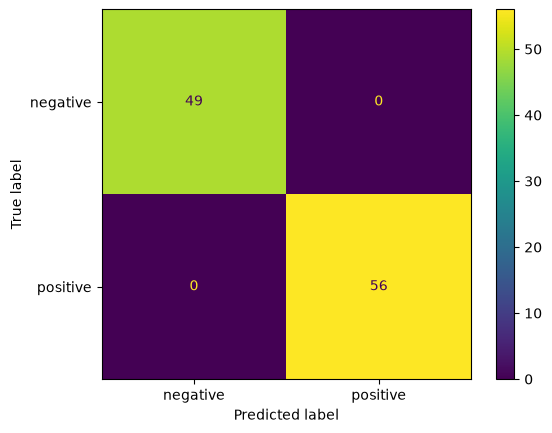

In [168]:
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logistic_model.classes_).plot()